In [1]:
# Настройка проекта
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import meep as mp
import numpy as np
import pandas as pd
mp.verbosity(0) # decrease amount of output

1

In [18]:
def plot_efficiency_manual(
    angles=None,
    wavelengths=None,
    kpd_values=None,
    csv_path=None,
    column_name=None,
    title="Focusing efficiency",
    save_path=None,
    vector_format="pdf",
    dpi=300,
    y_limits=None
):
    """
    Plots efficiency metrics based on provided data or extracted from a CSV file.

    Parameters:
    - angles: list or array of angle values (required if csv_path is None).
    - wavelengths: list or array of wavelength values (required if csv_path is None).
    - kpd_values: 2D array of efficiency values, shape (len(angles), len(wavelengths)) (required if csv_path is None).
    - csv_path: Path to the CSV file (optional; if provided, data will be extracted from the file).
    - column_name: Name of the column in the CSV to use for efficiency values (required if csv_path is provided).
    - title: Title of the plot.
    - save_path: Path to save the figure (optional).
    - vector_format: Format for saving the vector figure (default: 'pdf').
    - dpi: Resolution for saving the figure.
    - y_limits: tuple (ymin, ymax) or None; if specified, fixes the Y-axis range.

    The function supports two modes:
    1. Provide angles, wavelengths, and kpd_values directly.
    2. Provide csv_path and column_name to extract data from the CSV file automatically.
    """

    if csv_path is not None:
        if column_name is None:
            raise ValueError("column_name must be provided when csv_path is specified.")
        if kpd_values is not None or angles is not None or wavelengths is not None:
            print("Warning: Ignoring provided angles, wavelengths, and kpd_values when csv_path is specified.")

        df = pd.read_csv(csv_path)
        
        # Extract unique angles in the order they appear
        angles = df['angle'].drop_duplicates().values
        
        # Extract unique wavelengths and sort them
        wavelengths = sorted(df['wave'].unique())
        
        num_angles = len(angles)
        num_waves = len(wavelengths)
        
        kpd_values = np.zeros((num_angles, num_waves))
        
        for i, ang in enumerate(angles):
            df_ang = df[df['angle'] == ang].sort_values(by='wave')
            if len(df_ang) != num_waves:
                raise ValueError(f"Mismatch in number of wavelengths for angle {ang}. Expected {num_waves}, found {len(df_ang)}.")
            kpd_values[i, :] = df_ang[column_name].values

    elif kpd_values is not None:
        if angles is None or wavelengths is None:
            raise ValueError("angles and wavelengths must be provided when kpd_values is specified.")
        kpd_values = np.array(kpd_values)
        if kpd_values.shape != (len(angles), len(wavelengths)):
            raise ValueError("kpd_values must have shape (len(angles), len(wavelengths)).")
    else:
        raise ValueError("Must provide either csv_path and column_name, or angles, wavelengths, and kpd_values.")

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "axes.labelsize": 13,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.linewidth": 1.0,
    })

    mean_vals = np.mean(kpd_values, axis=1)
    std_vals = np.std(kpd_values, axis=1)

    plt.figure(figsize=(8, 5))

    for j, wl in enumerate(wavelengths):
        plt.scatter(
            angles,
            kpd_values[:, j],
            label=f"λ = {wl} μm",
            s=40
        )

    plt.errorbar(
        angles, mean_vals, yerr=std_vals,
        fmt="k-o", capsize=4, elinewidth=1.1, linewidth=1.8,
        label="average"
    )

    plt.xlabel("Angle (°)")
    plt.ylabel("Efficiency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    # Apply Y-axis limits if specified
    if y_limits is not None:
        plt.ylim(y_limits)

    plt.tight_layout()

    if save_path is not None:
        if not save_path.lower().endswith(f".{vector_format}"):
            save_path += f".{vector_format}"
        plt.savefig(save_path, format=vector_format, dpi=dpi, bbox_inches="tight")
        print(f"✅ Figure saved to: {save_path}")

    plt.show()
    
def plot_efficiency_v1(
    csv_path,
    column_name,
    title="Focusing efficiency",
    save_path=None,
    vector_format="pdf",
    dpi=300,
    y_limits=None
):
    """
    Plots efficiency metrics extracted from a CSV file.

    Parameters:
    - csv_path: Path to the CSV file (required).
    - column_name: Name of the column in the CSV to use for efficiency values (required).
    - title: Title of the plot.
    - save_path: Path to save the figure (optional).
    - vector_format: Format for saving the vector figure (default: 'pdf').
    - dpi: Resolution for saving the figure.
    - y_limits: tuple (ymin, ymax) or None; if specified, fixes the Y-axis range.
    """

    if column_name is None:
        raise ValueError("column_name must be provided.")

    df = pd.read_csv(csv_path)
    
    # Extract unique angles in the order they appear
    angles = df['angle'].drop_duplicates().values
    
    # Extract unique wavelengths and sort them
    wavelengths = sorted(df['wave'].unique())
    
    num_angles = len(angles)
    num_waves = len(wavelengths)
    
    kpd_values = np.zeros((num_angles, num_waves))
    
    for i, ang in enumerate(angles):
        df_ang = df[df['angle'] == ang].sort_values(by='wave')
        if len(df_ang) != num_waves:
            raise ValueError(f"Mismatch in number of wavelengths for angle {ang}. Expected {num_waves}, found {len(df_ang)}.")
        kpd_values[i, :] = df_ang[column_name].values

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "axes.labelsize": 13,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.linewidth": 1.0,
    })

    mean_vals = np.mean(kpd_values, axis=1)
    std_vals = np.std(kpd_values, axis=1)

    plt.figure(figsize=(8, 5))

    for j, wl in enumerate(wavelengths):
        plt.scatter(
            angles,
            kpd_values[:, j],
            label=f"λ = {wl} μm",
            s=40
        )

    plt.errorbar(
        angles, mean_vals, yerr=std_vals,
        fmt="k-o", capsize=4, elinewidth=1.1, linewidth=1.8,
        label="average"
    )

    plt.xlabel("Angle (°)")
    plt.ylabel("Efficiency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    # Apply Y-axis limits if specified
    if y_limits is not None:
        plt.ylim(y_limits)

    plt.tight_layout()

    if save_path is not None:
        if not save_path.lower().endswith(f".{vector_format}"):
            save_path += f".{vector_format}"
        plt.savefig(save_path, format=vector_format, dpi=dpi, bbox_inches="tight")
        print(f"✅ Figure saved to: {save_path}")

    plt.show()

def plot_efficiency_v2(
    csv_path,
    column_name,
    title="Focusing efficiency",
    save_path=None,
    vector_format="pdf",
    dpi=300,
    kpd_ymax=None,
    show_std_curve=False,
    std_ymax=None
):
    """
    Plots efficiency metrics extracted from a CSV file.

    Parameters:
    - csv_path: Path to the CSV file (required).
    - column_name: Name of the column in the CSV to use for efficiency values (required).
    - title: Title of the plot.
    - save_path: Path to save the figure (optional).
    - vector_format: Format for saving the vector figure (default: 'pdf').
    - dpi: Resolution for saving the figure.
    - kpd_ymax: tuple (ymin, ymax) or None; if specified, fixes the Y-axis range.
    - show_std_curve: If True, adds a secondary y-axis with a curve for standard deviation values (default: False).
    - std_ymax: If specified, fixes the maximum value for the secondary y-axis (default: None).
    """

    if column_name is None:
        raise ValueError("column_name must be provided.")

    df = pd.read_csv(csv_path)
    
    # Extract unique angles in the order they appear
    angles = df['angle'].drop_duplicates().values
    
    # Extract unique wavelengths and sort them
    wavelengths = sorted(df['wave'].unique())
    
    num_angles = len(angles)
    num_waves = len(wavelengths)
    
    kpd_values = np.zeros((num_angles, num_waves))
    
    for i, ang in enumerate(angles):
        df_ang = df[df['angle'] == ang].sort_values(by='wave')
        if len(df_ang) != num_waves:
            raise ValueError(f"Mismatch in number of wavelengths for angle {ang}. Expected {num_waves}, found {len(df_ang)}.")
        kpd_values[i, :] = df_ang[column_name].values

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "axes.labelsize": 13,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.linewidth": 1.0,
    })

    mean_vals = np.mean(kpd_values, axis=1)
    std_vals = np.std(kpd_values, axis=1)

    fig, ax = plt.subplots(figsize=(8, 5))

    for j, wl in enumerate(wavelengths):
        ax.scatter(
            angles,
            kpd_values[:, j],
            label=f"λ = {wl} μm",
            s=40
        )

    ax.errorbar(
        angles, mean_vals, yerr=std_vals,
        fmt="k-", capsize=4, elinewidth=1.1, linewidth=1.8,
        label="average"
    )

    ax.set_xlabel("angle (deg)")
    ax.set_ylabel("efficiency")
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.6)

    # Apply Y-axis limits if specified
    if kpd_ymax is not None:
        ax.set_ylim(kpd_ymax)

    if show_std_curve:
        ax2 = ax.twinx()
        ax2.plot(
            angles, std_vals,
            "r--", linewidth=1.8,
            label="std dev"
        )
        ax2.set_ylabel("standard deviation")
        if std_ymax is not None:
            ax2.set_ylim(0, std_ymax)
            
        ax2.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    # Combine legends from both axes
    handles, labels = ax.get_legend_handles_labels()
    if show_std_curve:
        handles2, labels2 = ax2.get_legend_handles_labels()
        handles += handles2
        labels += labels2
    ax.legend(handles, labels)

    plt.tight_layout()

    if save_path is not None:
        if not save_path.lower().endswith(f".{vector_format}"):
            save_path += f".{vector_format}"
        plt.savefig(save_path, format=vector_format, dpi=dpi, bbox_inches="tight")
        print(f"✅ Figure saved to: {save_path}")

    plt.show()

✅ Figure saved to: res_function.pdf


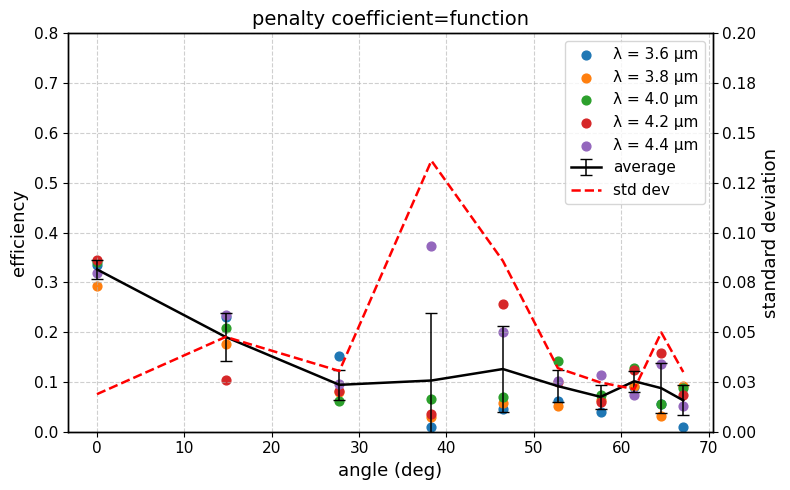

✅ Figure saved to: res_const.pdf


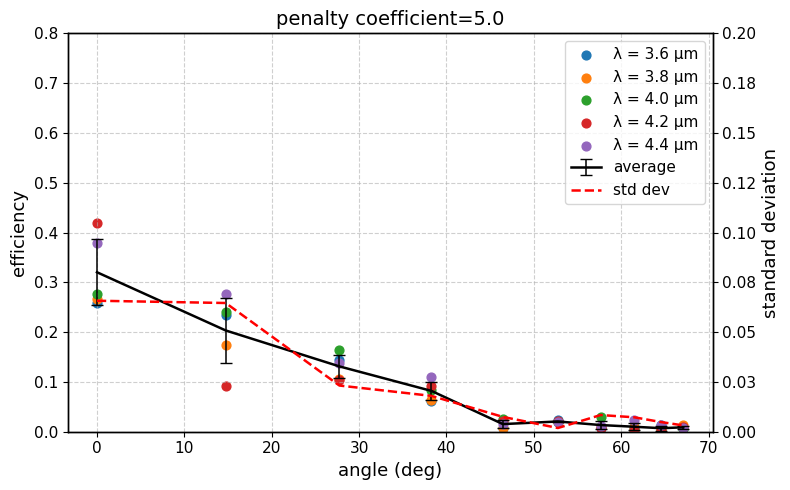

✅ Figure saved to: res_0.pdf


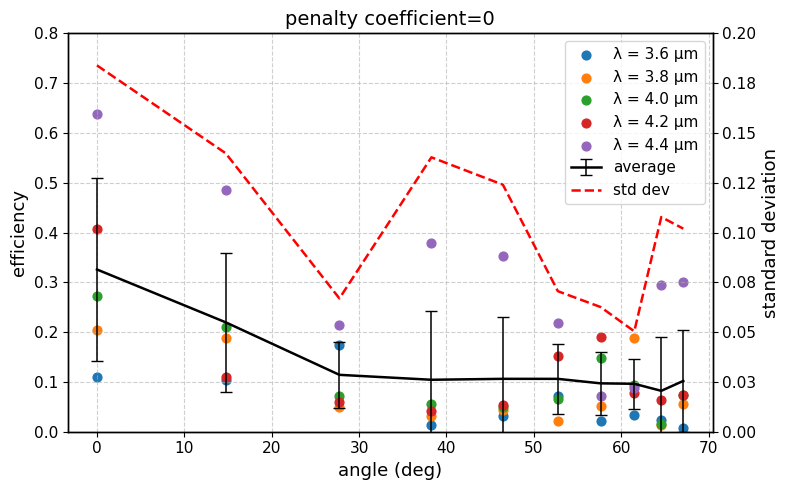

In [19]:
plot_efficiency_v2(csv_path="efficiency_plane_function.csv", column_name="EER_rel", save_path="res_function", vector_format="pdf", title="penalty coefficient=function", show_std_curve=True, kpd_ymax=(0.0, 0.8), std_ymax=0.2)
plot_efficiency_v2(csv_path="efficiency_plane_const.csv", column_name="EER_rel", save_path="res_const", vector_format="pdf", title="penalty coefficient=5.0", show_std_curve=True, kpd_ymax=(0.0, 0.8), std_ymax=0.2)
plot_efficiency_v2(csv_path="efficiency_plane_0.csv", column_name="EER_rel", save_path="res_0", vector_format="pdf", title="penalty coefficient=0", show_std_curve=True, kpd_ymax=(0.0, 0.8), std_ymax=0.2)

In [21]:
def plot_penalty_vs_angle(
    angle_max=70.0,
    n_points=100,
    save_path="penalty_vs_angle.pdf",
):
    # ---------- reference data ----------
    angles_ref = np.array([0.0, 20.0, 40.0])
    penalty_ref = np.array([20.0, 5.0, 0.05])
    penalty_min = 0.05
    angle_saturation = 40.0
    
    # angles_ref = np.array([0.0, 20.0, 40.0])
    # penalty_ref = np.array([5.0, 5.0, 5.0])
    # penalty_min = 5.0
    # angle_saturation = 0

    # ---------- log-space approximation ----------
    log_penalty_ref = np.log(penalty_ref)

    A = np.vstack([
        angles_ref**2,
        angles_ref,
        np.ones_like(angles_ref)
    ]).T

    a, b, c = np.linalg.solve(A, log_penalty_ref)

    # ---------- angle grid ----------
    angles = np.linspace(0.0, angle_max, n_points)
    penalty = np.zeros_like(angles)

    for i, angle in enumerate(angles):
        if angle <= angle_saturation:
            log_penalty = a * angle**2 + b * angle + c
            penalty[i] = np.exp(log_penalty)
        else:
            penalty[i] = penalty_min

    # ---------- plotting style ----------
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "axes.labelsize": 13,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.linewidth": 1.0,
    })

    # ---------- plot ----------
    fig, ax = plt.subplots(figsize=(6.5, 4.5))

    ax.plot(angles, penalty, label="penalty coefficient")
    # ax.axvline(angle_saturation, linestyle="--", linewidth=1.0,
    #            label="Saturation angle")

    ax.set_xlabel("angle (deg)")
    ax.set_ylabel("penalty coefficient")
    ax.set_xlim(0, angle_max)
    # ax.set_yscale("log")
    # ax.grid(True, which="both", linewidth=0.5, alpha=0.6)
    # ax.legend()

    plt.tight_layout()
    plt.savefig(save_path, format="pdf")
    plt.close(fig)

In [22]:
plot_penalty_vs_angle(save_path="1.pdf")

In [4]:
def plot_static_penalty(
    penalty_value=0.0,
    angle_max=70.0,
    n_points=100,
    save_path="penalty_static_5_linear.pdf",
):
    # ---------- angle grid ----------
    angles = np.linspace(0.0, angle_max, n_points)
    penalty = np.full_like(angles, penalty_value, dtype=float)

    # ---------- plotting style ----------
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "axes.labelsize": 13,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.linewidth": 1.0,
    })

    # ---------- plot ----------
    fig, ax = plt.subplots(figsize=(6.5, 4.5))

    ax.plot(
        angles,
        penalty,
        label=f"Penalty = {penalty_value}",
        linewidth=2.0,
    )

    ax.set_xlabel("angle (deg)")
    ax.set_ylabel("penalty coefficient")
    ax.set_xlim(0, angle_max)
    # ax.grid(True, linewidth=0.5, alpha=0.6)
    # ax.legend()

    plt.tight_layout()
    plt.savefig(save_path, format="pdf")
    plt.close(fig)

In [5]:
plot_static_penalty(save_path="0.pdf")